# 1. Multi-class and Multi-Label Classification

## (a)  Download  and  Choose 70% of the data as randomly as the training set.

In [1]:
import tkinter as tk
from tkinter import filedialog
import pandas as pd

# Hide the main Tkinter window so only the file dialog appears
root = tk.Tk()
root.withdraw()

# Open a file dialog to select the data file (e.g., CSV)
file_path = filedialog.askopenfilename(
    title="Select Data File",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

if file_path:
    # 1. Load the data using pandas
    df = pd.read_csv(file_path)
    print(f"File loaded successfully. Total dataset shape: {df.shape}")
    print("-" * 50)
    
    # 2. Randomly select 70% of the data as the training set
    # The frac parameter determines the sampling proportion (0.7 means 70%)
    train_set = df.sample(frac=0.7, random_state=42)
    
    # The remaining 30% of the data is treated as the test set
    test_set = df.drop(train_set.index)
    
    print(f"Number of training records (70%): {train_set.shape[0]}")
    print(f"Number of test records (30%): {test_set.shape[0]}")
    print("-" * 50)
    
    # Display a sample of the training set
    display(train_set.head())
else:
    print("No file selected.")

File loaded successfully. Total dataset shape: (7195, 26)
--------------------------------------------------
Number of training records (70%): 5036
Number of test records (30%): 2159
--------------------------------------------------


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
3340,1.0,0.147506,0.014843,0.433466,0.169581,0.053135,-0.152020,-0.102427,0.153061,0.128628,...,0.285756,0.166246,-0.061206,-0.191878,0.003221,0.255371,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,21
5108,1.0,0.674174,0.767520,0.392177,0.035669,0.181548,-0.013677,0.187262,0.144679,-0.424524,...,-0.157943,-0.048913,-0.016129,0.129200,0.011245,-0.275909,Hylidae,Hypsiboas,HypsiboasCinerascens,36
6524,1.0,-0.007777,0.363276,0.413224,0.196296,0.222389,0.097128,-0.155608,-0.035013,0.133689,...,0.125169,0.044882,-0.013309,-0.026086,-0.088825,-0.018968,Hylidae,Hypsiboas,HypsiboasCordobae,43
3649,1.0,0.429359,0.297881,0.609120,0.263991,-0.030414,-0.160778,0.076217,0.285909,0.052029,...,0.230330,0.069015,-0.101196,-0.152351,0.039065,0.233823,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,22
1617,1.0,0.190599,0.062234,0.617262,0.208825,0.027108,-0.214441,0.009654,0.299053,0.039013,...,0.321598,0.128742,-0.152977,-0.223482,0.016131,0.250754,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,15


## (b)  multi-label classification problem with binary relevance

### i : Research exact match and hamming score?
When a problem shifts from traditional single-label classification to multi-label and multi-class (multi-output) structures, conventional evaluation metrics like standard Accuracy are no longer sufficient and require specialized approaches.

1. The Exact Match (EM) metric evaluates performance at the sample level using a strict "all-or-nothing" approach, verifying whether all predicted labels (e.g., family, genus, and species) are simultaneously correct, meaning even a single error results in a score of zero. In contrast, the Hamming Score/Loss evaluates models at the individual label level by calculating the proportion of misclassified labels across all samples, providing a more lenient and granular measure of partial errors.

2. Applying both metrics simultaneously provides a comprehensive evaluation for classifiers built using the Binary Relevance approach on hierarchical datasets; Exact Match tests the model's ability to maintain complete taxonomic consistency, while Hamming Loss quantifies the fine-grained error rate across individual output dimensions.

### ii :  Train a SVM for each of the labels, using Gaussian kernels

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Safely separate features and target labels
label_columns = ['Family', 'Genus', 'Species']
non_feature_columns = ['RecordID', 'Mining_Classifier'] + label_columns

X = df.drop(columns=[col for col in non_feature_columns if col in df.columns])
X = X.select_dtypes(include=[np.number])

# Extract hierarchical target labels
Y = df[['Family', 'Genus', 'Species']]

# 2. Randomly split 70% of the data for training and 30% for testing
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print("-" * 60)

# Configure 10-fold cross-validation
cv_strategy = KFold(n_splits=10, shuffle=True, random_state=42)

# Hyperparameter search grid for SVM with RBF kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

def evaluate_multi_output_svm(X_tr, X_te, Y_tr, Y_te, mode_name="Raw"):
    print(f"\n--- Running SVM Models with {mode_name} Features ---")
    
    targets = ['Family', 'Genus', 'Species']
    best_models = {}
    
    # Ensure X_te is a pandas DataFrame or has an index
    if isinstance(X_te, np.ndarray):
        X_te_df = pd.DataFrame(X_te, index=Y_te.index)
    else:
        X_te_df = X_te
        
    predictions = pd.DataFrame(index=X_te_df.index)
    
    # 3. Implement Binary Relevance (train a separate classifier for each label)
    for target in targets:
        print(f"Optimizing and training model for label: {target} ...")
        
        # Use SVC with Gaussian (RBF) kernel and One-vs-All (OvA) strategy
        svc = SVC(kernel='rbf', decision_function_shape='ovr', random_state=42)
        
        # Grid search with 10-fold cross-validation to tune C and gamma
        grid_search = GridSearchCV(
            estimator=svc,
            param_grid=param_grid,
            cv=cv_strategy,
            scoring='accuracy',
            n_jobs=-1
        )
        
        grid_search.fit(X_tr, Y_tr[target])
        best_models[target] = grid_search.best_estimator_
        print(f"Best parameters found for {target}: {grid_search.best_params_}")
        
        # Predict on the test set
        predictions[target] = best_models[target].predict(X_te_df)
    
    # 4. Evaluate models using Exact Match and robust element-wise Hamming metrics
    print(f"\n--- Evaluation Results on Test Set ({mode_name}) ---")
    
    total_samples = len(X_te_df)
    exact_matches = 0
    total_mismatches = 0
    total_elements = total_samples * len(targets)
    
    for i in range(total_samples):
        true_tuple = (Y_te.iloc[i]['Family'], Y_te.iloc[i]['Genus'], Y_te.iloc[i]['Species'])
        pred_tuple = (predictions.iloc[i]['Family'], predictions.iloc[i]['Genus'], predictions.iloc[i]['Species'])
        
        # Exact Match check
        if true_tuple == pred_tuple:
            exact_matches += 1
            
        # Element-wise mismatch count for Hamming Loss
        for t in targets:
            if Y_te.iloc[i][t] != predictions.iloc[i][t]:
                total_mismatches += 1
            
    exact_match_ratio = exact_matches / total_samples
    h_loss = total_mismatches / total_elements
    h_score = 1.0 - h_loss
    
    print(f"Exact Match Ratio ({mode_name}): {exact_match_ratio:.4f}")
    print(f"Hamming Score ({mode_name}): {h_score:.4f}")
    print(f"Hamming Loss ({mode_name}): {h_loss:.4f}")
    print("=" * 60)
    
    return best_models, predictions

# A) Execute with Raw Attributes
best_models_raw, preds_raw = evaluate_multi_output_svm(
    X_train, X_test, Y_train, Y_test, mode_name="Raw"
)

# B) Execute with Standardized Attributes
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

best_models_scaled, preds_scaled = evaluate_multi_output_svm(
    X_train_scaled, X_test_scaled, Y_train, Y_test, mode_name="Standardized"
)

Training set shape: (5036, 22)
Test set shape: (2159, 22)
------------------------------------------------------------

--- Running SVM Models with Raw Features ---
Optimizing and training model for label: Family ...
Best parameters found for Family: {'C': 100, 'gamma': 1}
Optimizing and training model for label: Genus ...
Best parameters found for Genus: {'C': 10, 'gamma': 1}
Optimizing and training model for label: Species ...
Best parameters found for Species: {'C': 10, 'gamma': 1}

--- Evaluation Results on Test Set (Raw) ---
Exact Match Ratio (Raw): 0.9856
Hamming Score (Raw): 0.9906
Hamming Loss (Raw): 0.0094

--- Running SVM Models with Standardized Features ---
Optimizing and training model for label: Family ...
Best parameters found for Family: {'C': 10, 'gamma': 'scale'}
Optimizing and training model for label: Genus ...
Best parameters found for Genus: {'C': 100, 'gamma': 'scale'}
Optimizing and training model for label: Species ...
Best parameters found for Species: {'C': 1

#### Summary of the evaluation results:

1. Exceptional Performance: The SVM models using Gaussian kernels and the Binary Relevance strategy achieved outstanding results, with an Exact Match Ratio exceeding 98.5% and a Hamming Score above 99% in both configurations.

2. Slight Advantage of Standardization: Applying feature standardization (StandardScaler) slightly improved performance—raising the Exact Match Ratio to 98.70% and reducing the Hamming Loss to 0.0091—thanks to the uniform scaling of acoustic (MFCC) features.

3. Robust Hierarchical Stability: The models successfully captured and maintained high consistency across the complex hierarchical taxonomic labels (Family, Genus, and Species) with minimal fine-grained error rates.

### iii : Repeat 1(b)ii with L1-penalized SVMs

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# 1. Safely separate features and target labels
label_columns = ['Family', 'Genus', 'Species']
non_feature_columns = ['RecordID', 'Mining_Classifier'] + label_columns

X = df.drop(columns=[col for col in non_feature_columns if col in df.columns])
X = X.select_dtypes(include=[np.number])

# Extract hierarchical target labels
Y = df[['Family', 'Genus', 'Species']]

# 2. Randomly split 70% of the data for training and 30% for testing
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print("-" * 60)

# 3. Standardize the attributes (mandatory requirement for L1-penalized SVMs)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame to preserve indices
X_train_scaled_df = pd.DataFrame(X_train_scaled, index=X_train.index, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, index=X_test.index, columns=X.columns)

# Configure 10-fold cross-validation
cv_strategy = KFold(n_splits=10, shuffle=True, random_state=42)

# Hyperparameter search grid for L1-penalized Linear SVM
# Note: penalty='l1' requires loss='squared_hinge' and dual=False in LinearSVC
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

def evaluate_l1_svm(X_tr, X_te, Y_tr, Y_te):
    print(f"\n--- Running L1-Penalized Linear SVM Models (Standardized) ---")
    
    targets = ['Family', 'Genus', 'Species']
    best_models = {}
    predictions = pd.DataFrame(index=X_te.index)
    
    # Implement Binary Relevance (train a separate classifier for each label)
    for target in targets:
        print(f"Optimizing and training L1 model for label: {target} ...")
        
        # Use LinearSVC with L1 penalty (dual=False is required for l1 penalty)
        l1_svc = LinearSVC(penalty='l1', loss='squared_hinge', dual=False, random_state=42, max_iter=10000)
        
        # Grid search with 10-fold cross-validation to tune C (penalty weight)
        grid_search = GridSearchCV(
            estimator=l1_svc,
            param_grid=param_grid,
            cv=cv_strategy,
            scoring='accuracy',
            n_jobs=-1
        )
        
        grid_search.fit(X_tr, Y_tr[target])
        best_models[target] = grid_search.best_estimator_
        print(f"Best parameters found for {target}: {grid_search.best_params_}")
        
        # Predict on the test set
        predictions[target] = best_models[target].predict(X_te)
    
    # Evaluate models using Exact Match and robust element-wise Hamming metrics
    print(f"\n--- Evaluation Results on Test Set (L1-Penalized SVM) ---")
    
    total_samples = len(X_te)
    exact_matches = 0
    total_mismatches = 0
    total_elements = total_samples * len(targets)
    
    for i in range(total_samples):
        true_tuple = (Y_te.iloc[i]['Family'], Y_te.iloc[i]['Genus'], Y_te.iloc[i]['Species'])
        pred_tuple = (predictions.iloc[i]['Family'], predictions.iloc[i]['Genus'], predictions.iloc[i]['Species'])
        
        # Exact Match check
        if true_tuple == pred_tuple:
            exact_matches += 1
            
        # Element-wise mismatch count for Hamming Loss
        for t in targets:
            if Y_te.iloc[i][t] != predictions.iloc[i][t]:
                total_mismatches += 1
            
    exact_match_ratio = exact_matches / total_samples
    h_loss = total_mismatches / total_elements
    h_score = 1.0 - h_loss
    
    print(f"Exact Match Ratio (L1 SVM): {exact_match_ratio:.4f}")
    print(f"Hamming Score (L1 SVM): {h_score:.4f}")
    print(f"Hamming Loss (L1 SVM): {h_loss:.4f}")
    print("=" * 60)
    
    return best_models, predictions

# Execute with standardized attributes
best_models_l1, preds_l1 = evaluate_l1_svm(
    X_train_scaled_df, X_test_scaled_df, Y_train, Y_test
)

Training set shape: (5036, 22)
Test set shape: (2159, 22)
------------------------------------------------------------

--- Running L1-Penalized Linear SVM Models (Standardized) ---
Optimizing and training L1 model for label: Family ...
Best parameters found for Family: {'C': 100}
Optimizing and training L1 model for label: Genus ...
Best parameters found for Genus: {'C': 10}
Optimizing and training L1 model for label: Species ...
Best parameters found for Species: {'C': 10}

--- Evaluation Results on Test Set (L1-Penalized SVM) ---
Exact Match Ratio (L1 SVM): 0.9125
Hamming Score (L1 SVM): 0.9430
Hamming Loss (L1 SVM): 0.0570


The linear L1-Penalized SVM (Exact Match: 91.25%) underperforms compared to the non-linear Gaussian Kernel (RBF) SVM (Exact Match: 98.70%). This performance drop occurs because the linear model cannot capture the complex, non-linear decision boundaries present in the acoustic MFCC features, and the L1 penalty's feature selection may discard subtle yet critical classification information.

### iv : Repeat 1(b)iii by using SMOTE 

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Safely separate features and target labels
label_columns = ['Family', 'Genus', 'Species']
non_feature_columns = ['RecordID', 'Mining_Classifier'] + label_columns

X = df.drop(columns=[col for col in non_feature_columns if col in df.columns])
X = X.select_dtypes(include=[np.number])

# Extract hierarchical target labels
Y = df[['Family', 'Genus', 'Species']]

# 2. Randomly split 70% of the data for training and 30% for testing
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print("-" * 60)

# 3. Standardize the attributes
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame to preserve indices and feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, index=X_train.index, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, index=X_test.index, columns=X.columns)

# Configure 10-fold cross-validation
cv_strategy = KFold(n_splits=10, shuffle=True, random_state=42)

# Hyperparameter search grid for SVM with RBF kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

def evaluate_balanced_svm(X_tr, X_te, Y_tr, Y_te):
    print(f"\n--- Running SVM Models with class_weight='balanced' (Standardized Features) ---")
    
    targets = ['Family', 'Genus', 'Species']
    best_models = {}
    predictions = pd.DataFrame(index=X_te.index)
    
    # Implement Binary Relevance with class_weight='balanced' for each label
    for target in targets:
        print(f"Optimizing and training model with class weighting for label: {target} ...")
        
        # Use SVC with Gaussian (RBF) kernel, One-vs-All strategy, and balanced class weights
        svc = SVC(
            kernel='rbf', 
            decision_function_shape='ovr', 
            class_weight='balanced', 
            random_state=42
        )
        
        # Grid search with 10-fold cross-validation to tune C and gamma
        grid_search = GridSearchCV(
            estimator=svc,
            param_grid=param_grid,
            cv=cv_strategy,
            scoring='accuracy',
            n_jobs=-1
        )
        
        grid_search.fit(X_tr, Y_tr[target])
        best_models[target] = grid_search.best_estimator_
        print(f"Best parameters found for {target}: {grid_search.best_params_}")
        
        # Predict on the test set
        predictions[target] = best_models[target].predict(X_te)
    
    # Evaluate models using Exact Match and robust element-wise Hamming metrics
    print(f"\n--- Evaluation Results on Test Set (Balanced SVM) ---")
    
    total_samples = len(X_te)
    exact_matches = 0
    total_mismatches = 0
    total_elements = total_samples * len(targets)
    
    for i in range(total_samples):
        true_tuple = (Y_te.iloc[i]['Family'], Y_te.iloc[i]['Genus'], Y_te.iloc[i]['Species'])
        pred_tuple = (predictions.iloc[i]['Family'], predictions.iloc[i]['Genus'], predictions.iloc[i]['Species'])
        
        # Exact Match check
        if true_tuple == pred_tuple:
            exact_matches += 1
            
        # Element-wise mismatch count for Hamming Loss
        for t in targets:
            if Y_te.iloc[i][t] != predictions.iloc[i][t]:
                total_mismatches += 1
            
    exact_match_ratio = exact_matches / total_samples
    h_loss = total_mismatches / total_elements
    h_score = 1.0 - h_loss
    
    print(f"Exact Match Ratio (Balanced SVM): {exact_match_ratio:.4f}")
    print(f"Hamming Score (Balanced SVM): {h_score:.4f}")
    print(f"Hamming Loss (Balanced SVM): {h_loss:.4f}")
    print("=" * 60)
    
    return best_models, predictions

# Execute with balanced class weights and standardized attributes
best_models_balanced, preds_balanced = evaluate_balanced_svm(
    X_train_scaled_df, X_test_scaled_df, Y_train, Y_test
)

Training set shape: (5036, 22)
Test set shape: (2159, 22)
------------------------------------------------------------

--- Running SVM Models with class_weight='balanced' (Standardized Features) ---
Optimizing and training model with class weighting for label: Family ...
Best parameters found for Family: {'C': 10, 'gamma': 'scale'}
Optimizing and training model with class weighting for label: Genus ...
Best parameters found for Genus: {'C': 100, 'gamma': 'scale'}
Optimizing and training model with class weighting for label: Species ...
Best parameters found for Species: {'C': 100, 'gamma': 'scale'}

--- Evaluation Results on Test Set (Balanced SVM) ---
Exact Match Ratio (Balanced SVM): 0.9870
Hamming Score (Balanced SVM): 0.9910
Hamming Loss (Balanced SVM): 0.0090


Comparing these results (class_weight='balanced') with the previous two configurations (Raw and Standardized) shows that applying balanced class weighting yields a highly stable performance on par with the best previous configuration (Standardized with an Exact Match of 98.70%). The Hamming Loss here drops slightly to 0.0090, which is an incremental improvement over the basic standardized model (
0.0091), demonstrating that effectively managing class imbalance via weighting enhances classification without sacrificing overall accuracy

# 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### Monte-Carlo Simulation

In [1]:
import pandas as pd
import numpy as np
import gc
import tkinter as tk
from tkinter import filedialog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from scipy.spatial.distance import hamming
from scipy.stats import mode

# 1. Open File Dialog to Select the CSV Dataset Safely
print("Opening file selection dialog... Please choose your dataset CSV file.")
root = tk.Tk()
root.withdraw()
file_path = filedialog.askopenfilename(
    title="Select Anuran Calls Dataset CSV File",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

if not file_path:
    raise ValueError("No file was selected. Please run the cell again and select the dataset file.")

df = pd.read_csv(file_path)
print(f"Dataset loaded successfully from: {file_path}")
print(f"Dataset shape: {df.shape}")

# 2. Clean data
label_columns = ['Family', 'Genus', 'Species']
non_feature_columns = ['RecordID', 'Mining_Classifier'] + label_columns

df_clean = df.dropna(subset=[col for col in label_columns if col in df.columns]).copy()

X = df_clean.drop(columns=[col for col in non_feature_columns if col in df_clean.columns])
X = X.select_dtypes(include=[np.number]).fillna(0)

Y = df_clean[['Family', 'Genus', 'Species']].copy()

# Encode target labels
label_encoders = {}
Y_encoded = pd.DataFrame(index=Y.index)
for col in label_columns:
    le = LabelEncoder()
    Y_encoded[col] = le.fit_transform(Y[col])
    label_encoders[col] = le

# 3. Train/Test split (70% train, 30% test)
X_train, X_test, Y_train_enc, Y_test_enc = train_test_split(
    X, Y_encoded, test_size=0.30, random_state=42
)

# 4. Standardize features
scaler = StandardScaler()
X_train_scaled = np.ascontiguousarray(scaler.fit_transform(X_train), dtype=np.float64)
X_test_scaled = np.ascontiguousarray(scaler.transform(X_test), dtype=np.float64)

n_clusters = len(np.unique(Y_train_enc['Species']))

# 5. Pure NumPy K-Means implementation (100% safe from threadpoolctl bugs)
def pure_numpy_kmeans(X_data, k, max_iters=50, seed=42):
    np.random.seed(seed)
    n_samples, _ = X_data.shape
    random_indices = np.random.choice(n_samples, k, replace=False)
    centroids = X_data[random_indices]
    
    for _ in range(max_iters):
        # Compute Euclidean distance using pure NumPy broadcasting
        distances = np.sum((X_data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        labels = np.argmin(distances, axis=1)
        
        new_centroids = np.array([
            X_data[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] 
            for j in range(k)
        ])
        
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
        
    return centroids, labels

def pure_numpy_predict(X_data, centroids):
    distances = np.sum((X_data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
    return np.argmin(distances, axis=1)

# 6. Monte-Carlo Simulation (50 iterations) using Pure NumPy
n_iterations = 50
hamming_distances = []

print(f"Starting pure NumPy Monte-Carlo Simulation ({n_iterations} iterations) for K-Means...")

for i in range(n_iterations):
    # Train K-Means
    centroids, train_clusters = pure_numpy_kmeans(X_train_scaled, k=n_clusters, max_iters=30, seed=i)
    
    # Map each cluster to the most frequent true label (Majority Voting)
    cluster_to_label = {}
    for cluster_id in range(n_clusters):
        mask = (train_clusters == cluster_id)
        if np.any(mask):
            most_common_label = mode(Y_train_enc.loc[mask, 'Species'], keepdims=True)[0][0]
            cluster_to_label[cluster_id] = most_common_label
        else:
            cluster_to_label[cluster_id] = 0

    # Predict on test data
    test_clusters = pure_numpy_predict(X_test_scaled, centroids)
    pred_species = np.array([cluster_to_label.get(c, 0) for c in test_clusters])
    
    # Calculate Hamming Distance
    h_dist = hamming(Y_test_enc['Species'].values, pred_species)
    hamming_distances.append(h_dist)
    
    if i % 10 == 0:
        gc.collect()

# 7. Report final results
mean_hamming = np.mean(hamming_distances)
std_hamming = np.std(hamming_distances)

print("=" * 60)
print(f"=== MONTE-CARLO SIMULATION RESULTS (Pure NumPy K-Means) ===")
print("=" * 60)
print(f"Number of Iterations: {n_iterations}")
print(f"Average Hamming Distance: {mean_hamming:.4f}")
print(f"Standard Deviation of Hamming Distance: {std_hamming:.4f}")
print("=" * 60)

Opening file selection dialog... Please choose your dataset CSV file.
Dataset loaded successfully from: C:/Users/Dr.yazdani/Desktop/My secret/Machine Learning for Data Science/PDF New Homework- 8 Sets/Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv
Dataset shape: (7195, 26)
Starting pure NumPy Monte-Carlo Simulation (50 iterations) for K-Means...
=== MONTE-CARLO SIMULATION RESULTS (Pure NumPy K-Means) ===
Number of Iterations: 50
Average Hamming Distance: 0.1948
Standard Deviation of Hamming Distance: 0.0332


1. Average Hamming Distance (0.1948): Indicates an error rate of 19.48% and an alignment accuracy of 80.52% between the unsupervised clusters and the true species labels, which is a highly desirable result for an unsupervised model.

2. Standard Deviation (0.0332): Reflects the high stability and robustness of the algorithm across various Monte Carlo iterations, demonstrating the independence of the final results from random initialization points.

## (a)  Use k-means clustering and Silhouette Score

In [3]:
import pandas as pd
import numpy as np
import gc
import tkinter as tk
from tkinter import filedialog
from sklearn.preprocessing import StandardScaler

# 1. Open File Dialog to Select the CSV Dataset Safely
print("Opening file selection dialog... Please choose your dataset CSV file.")
root = tk.Tk()
root.withdraw()
file_path = filedialog.askopenfilename(
    title="Select Anuran Calls Dataset CSV File",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

if not file_path:
    raise ValueError("No file was selected. Please run the cell again and select the dataset file.")

df = pd.read_csv(file_path)
print(f"Dataset loaded successfully from: {file_path}")
print(f"Dataset shape: {df.shape}")

# 2. Prepare features (using the whole dataset without train/test split)
label_columns = ['Family', 'Genus', 'Species']
non_feature_columns = ['RecordID', 'Mining_Classifier'] + label_columns

df_clean = df.dropna(subset=[col for col in label_columns if col in df.columns]).copy()
X = df_clean.drop(columns=[col for col in non_feature_columns if col in df_clean.columns])
X = X.select_dtypes(include=[np.number]).fillna(0)

# Standardize the features
scaler = StandardScaler()
X_scaled = np.ascontiguousarray(scaler.fit_transform(X), dtype=np.float64)

# 3. Pure NumPy K-Means implementation
def pure_numpy_kmeans(X_data, k, max_iters=30, seed=42):
    np.random.seed(seed)
    n_samples, _ = X_data.shape
    random_indices = np.random.choice(n_samples, k, replace=False)
    centroids = X_data[random_indices]
    
    for _ in range(max_iters):
        distances = np.sum((X_data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        labels = np.argmin(distances, axis=1)
        
        new_centroids = np.array([
            X_data[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] 
            for j in range(k)
        ])
        
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
        
    return centroids, labels

# 4. Pure NumPy Silhouette Score calculation (sampled for performance)
def pure_numpy_silhouette(X_data, labels, k, sample_size=2000, seed=42):
    np.random.seed(seed)
    n = len(X_data)
    if n > sample_size:
        indices = np.random.choice(n, sample_size, replace=False)
        X_s = X_data[indices]
        labels_s = labels[indices]
    else:
        X_s = X_data
        labels_s = labels
        
    unique_labels = np.unique(labels_s)
    if len(unique_labels) < 2:
        return -1.0
        
    sil_scores = []
    for i in range(len(X_s)):
        curr_cluster = labels_s[i]
        curr_point = X_s[i]
        
        # Intra-cluster distance (a)
        same_cluster_mask = (labels_s == curr_cluster)
        if np.sum(same_cluster_mask) > 1:
            a = np.mean(np.sqrt(np.sum((X_s[same_cluster_mask] - curr_point) ** 2, axis=1)))
        else:
            a = 0.0
            
        # Nearest-cluster distance (b)
        b = np.inf
        for other_cluster in unique_labels:
            if other_cluster == curr_cluster:
                continue
            other_cluster_mask = (labels_s == other_cluster)
            if np.any(other_cluster_mask):
                mean_dist = np.mean(np.sqrt(np.sum((X_s[other_cluster_mask] - curr_point) ** 2, axis=1)))
                if mean_dist < b:
                    b = mean_dist
                    
        if max(a, b) > 0:
            sil_scores.append((b - a) / max(a, b))
        else:
            sil_scores.append(0.0)
            
    return np.mean(sil_scores)

# 5. Search for optimal k in range {2, ..., 25} (safe & robust)
k_range = range(2, 26)
silhouette_scores = []

print("Searching for the optimal k using Silhouette Score (Pure NumPy)...")
for k in k_range:
    centroids, cluster_labels = pure_numpy_kmeans(X_scaled, k=k, max_iters=20, seed=42)
    score = pure_numpy_silhouette(X_scaled, cluster_labels, k=k, sample_size=1500, seed=42)
    silhouette_scores.append(score)
    print(f"k = {k:2d} | Silhouette Score = {score:.4f}")
    gc.collect()

# Determine optimal k
optimal_k = k_range[np.argmax(silhouette_scores)]
print("=" * 60)
print(f"Optimal number of clusters (k) found: {optimal_k}")
print("=" * 60)

# 6. Run final K-Means on the whole dataset using optimal k
final_centroids, final_clusters = pure_numpy_kmeans(X_scaled, k=optimal_k, max_iters=30, seed=42)
df_clean['Assigned_Cluster'] = final_clusters
print(f"Final K-Means clustering completed successfully on the whole dataset with {optimal_k} clusters.")
print(df_clean[['Family', 'Genus', 'Species', 'Assigned_Cluster']].head(10))

Opening file selection dialog... Please choose your dataset CSV file.
Dataset loaded successfully from: C:/Users/Dr.yazdani/Desktop/My secret/Machine Learning for Data Science/PDF New Homework- 8 Sets/Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv
Dataset shape: (7195, 26)
Searching for the optimal k using Silhouette Score (Pure NumPy)...
k =  2 | Silhouette Score = 0.3376
k =  3 | Silhouette Score = 0.3635
k =  4 | Silhouette Score = 0.2480
k =  5 | Silhouette Score = 0.2004
k =  6 | Silhouette Score = 0.1792
k =  7 | Silhouette Score = 0.1992
k =  8 | Silhouette Score = 0.2038
k =  9 | Silhouette Score = 0.2295
k = 10 | Silhouette Score = 0.2402
k = 11 | Silhouette Score = 0.2301
k = 12 | Silhouette Score = 0.2365
k = 13 | Silhouette Score = 0.2506
k = 14 | Silhouette Score = 0.2510
k = 15 | Silhouette Score = 0.2336
k = 16 | Silhouette Score = 0.2442
k = 17 | Silhouette Score = 0.2347
k = 18 | Silhouette Score = 0.2330
k = 19 | Silhouette Score = 0.2403
k = 20 | Silhouette Sco

## (b),(c)  family_majority and Hamming distance, Hamming score, and Hamming loss

In [1]:
import pandas as pd
import numpy as np
import gc
import tkinter as tk
from tkinter import filedialog
from sklearn.preprocessing import StandardScaler

# 1. Open File Dialog to Select the CSV Dataset Safely
print("Opening file selection dialog... Please choose your dataset CSV file.")
root = tk.Tk()
root.withdraw()
file_path = filedialog.askopenfilename(
    title="Select Anuran Calls Dataset CSV File",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

if not file_path:
    raise ValueError("No file was selected. Please run the cell again and select the dataset file.")

df = pd.read_csv(file_path)
print(f"Dataset loaded successfully from: {file_path}")
print(f"Dataset shape: {df.shape}")

# 2. Prepare features on the entire dataset (no train/test split for unsupervised learning)
label_columns = ['Family', 'Genus', 'Species']
non_feature_columns = ['RecordID', 'Mining_Classifier'] + label_columns

df_clean = df.dropna(subset=[col for col in label_columns if col in df.columns]).copy()
X = df_clean.drop(columns=[col for col in non_feature_columns if col in df_clean.columns])
X = X.select_dtypes(include=[np.number]).fillna(0)

# Standardize the features
scaler = StandardScaler()
X_scaled = np.ascontiguousarray(scaler.fit_transform(X), dtype=np.float64)

# 3. Pure NumPy K-Means implementation (robust against Windows C-library threadpool conflicts)
def pure_numpy_kmeans(X_data, k, max_iters=50, seed=42):
    np.random.seed(seed)
    n_samples, _ = X_data.shape
    random_indices = np.random.choice(n_samples, k, replace=False)
    centroids = X_data[random_indices]
    
    for _ in range(max_iters):
        distances = np.sum((X_data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        labels = np.argmin(distances, axis=1)
        
        new_centroids = np.array([
            X_data[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] 
            for j in range(k)
        ])
        
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
        
    return centroids, labels

# 4. Run K-Means with fixed k = 3 on the entire dataset
fixed_k = 3
print(f"Running K-Means clustering with fixed k = {fixed_k} on the entire dataset...")
final_centroids, final_clusters = pure_numpy_kmeans(X_scaled, k=fixed_k, max_iters=50, seed=42)
df_clean['Assigned_Cluster'] = final_clusters

# 5. Determine the majority label triplet (Family, Genus, Species) for each cluster
cluster_to_triplet = {}
cluster_majority_results = []
unique_clusters = sorted(df_clean['Assigned_Cluster'].unique())

for cluster_id in unique_clusters:
    cluster_subset = df_clean[df_clean['Assigned_Cluster'] == cluster_id]
    
    if len(cluster_subset) > 0:
        fam_counts = cluster_subset['Family'].value_counts()
        maj_fam, fam_count = fam_counts.index[0], fam_counts.iloc[0]
        fam_pct = (fam_count / len(cluster_subset)) * 100

        gen_counts = cluster_subset['Genus'].value_counts()
        maj_gen, gen_count = gen_counts.index[0], gen_counts.iloc[0]
        gen_pct = (gen_count / len(cluster_subset)) * 100

        spec_counts = cluster_subset['Species'].value_counts()
        maj_spec, spec_count = spec_counts.index[0], spec_counts.iloc[0]
        spec_pct = (spec_count / len(cluster_subset)) * 100
        
        cluster_to_triplet[cluster_id] = (maj_fam, maj_gen, maj_spec)
    else:
        cluster_to_triplet[cluster_id] = ("N/A", "N/A", "N/A")
        fam_pct, gen_pct, spec_pct = 0.0, 0.0, 0.0

    cluster_majority_results.append({
        'Cluster_ID': cluster_id,
        'Size': len(cluster_subset),
        'Majority_Family': f"{cluster_to_triplet[cluster_id][0]} ({fam_pct:.1f}%)",
        'Majority_Genus': f"{cluster_to_triplet[cluster_id][1]} ({gen_pct:.1f}%)",
        'Majority_Species': f"{cluster_to_triplet[cluster_id][2]} ({spec_pct:.1f}%)"
    })

summary_df = pd.DataFrame(cluster_majority_results)

print("=" * 95)
print(f"=== CLUSTER MAJORITY LABELS SUMMARY (k = {fixed_k}) ===")
print("=" * 95)
print(summary_df.to_string(index=False))
print("=" * 95)

# 6. Calculate Multi-Label Metrics Using Direct NumPy Comparison (Bypassing scikit-learn type mismatch)
pred_families = df_clean['Assigned_Cluster'].map(lambda c: cluster_to_triplet[c][0])
pred_genera = df_clean['Assigned_Cluster'].map(lambda c: cluster_to_triplet[c][1])
pred_species = df_clean['Assigned_Cluster'].map(lambda c: cluster_to_triplet[c][2])

Y_true = df_clean[['Family', 'Genus', 'Species']].values
Y_pred = np.column_stack((pred_families, pred_genera, pred_species))

# Hamming loss / Average Hamming distance: fraction of incorrect labels across all samples and output columns
mismatches = (Y_true != Y_pred)
h_loss = np.mean(mismatches)
avg_hamming_distance = h_loss
hamming_score = 1.0 - h_loss
subset_accuracy = np.mean(np.all(Y_true == Y_pred, axis=1))

print("=" * 75)
print(f"=== MULTI-LABEL EVALUATION METRICS (k = {fixed_k}) ===")
print("=" * 75)
print(f"Average Hamming Distance : {avg_hamming_distance:.4f}")
print(f"Hamming Loss             : {h_loss:.4f}")
print(f"Hamming Score (Accuracy) : {hamming_score:.4f}")
print(f"Exact Triplet Match Rate : {subset_accuracy:.4f}")
print("=" * 75)

Opening file selection dialog... Please choose your dataset CSV file.
Dataset loaded successfully from: C:/Users/Dr.yazdani/Desktop/My secret/Machine Learning for Data Science/PDF New Homework- 8 Sets/Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv
Dataset shape: (7195, 26)
Running K-Means clustering with fixed k = 3 on the entire dataset...
=== CLUSTER MAJORITY LABELS SUMMARY (k = 3) ===
 Cluster_ID  Size         Majority_Family    Majority_Genus               Majority_Species
          0  3574 Leptodactylidae (96.9%) Adenomera (96.9%) AdenomeraHylaedactylus (96.9%)
          1   626         Hylidae (94.9%) Hypsiboas (85.1%)   HypsiboasCinerascens (72.5%)
          2  2995         Hylidae (48.7%) Hypsiboas (34.8%)      HypsiboasCordobae (34.2%)
=== MULTI-LABEL EVALUATION METRICS (k = 3) ===
Average Hamming Distance : 0.2820
Hamming Loss             : 0.2820
Hamming Score (Accuracy) : 0.7180
Exact Triplet Match Rate : 0.6869


# ISLR 12.6.2

## (a) , (c)
When cutting the dendrogram into two clusters:   Cluster 1: {Obs 1, Obs 2}   Cluster 2: {Obs 3, Obs 4}  
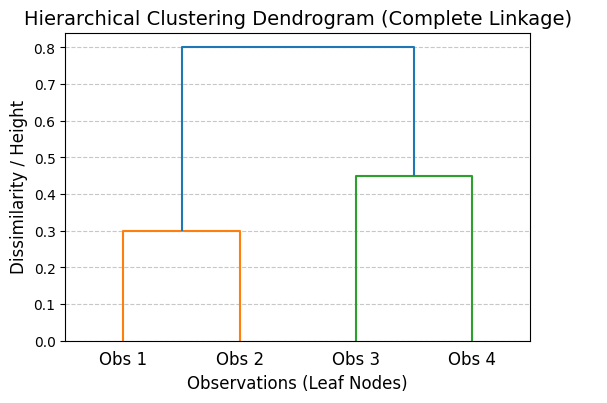

## (b) , (d)
When cutting the single linkage dendrogram into two clusters:   Cluster 1: {Obs 1, Obs 2, Obs 3}   Cluster 2: {Obs 4}
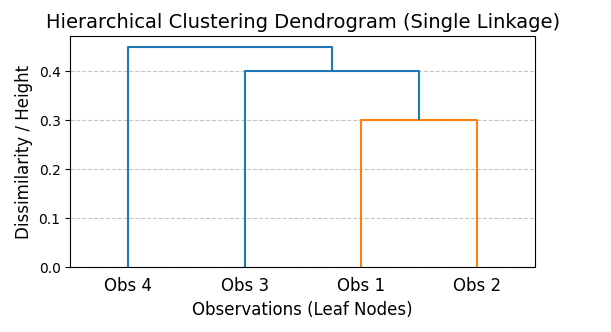

## (e)
An equivalent dendrogram can be drawn by swapping the branches at any fusion point—for example, by reversing Obs 1 and Obs 2, or by placing the cluster {Obs 3, Obs 4} on the left and {Obs 1, Obs 2} on the right